In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings

warnings.filterwarnings("ignore")

sns.set(style="whitegrid")

df= pd.read_csv("patients.csv")
df.head()

,patient_id,name,age,arrival_date,departure_date,service,satisfaction
0,PAT-09484753,Richard Rodriguez,24,2025-03-16,2025-03-22,surgery,61
1,PAT-f0644084,Shannon Walker,6,2025-12-13,2025-12-14,surgery,83
2,PAT-ac6162e4,Julia Torres,24,2025-06-29,2025-07-05,general_medicine,83
3,PAT-3dda2bb5,Crystal Johnson,32,2025-10-12,2025-10-23,emergency,81
4,PAT-08591375,Garrett Lin,25,2025-02-18,2025-02-25,ICU,76


In [30]:
df.shape

(1000, 7)

In [31]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   patient_id      1000 non-null   str  
 1   name            1000 non-null   str  
 2   age             1000 non-null   int64
 3   arrival_date    1000 non-null   str  
 4   departure_date  1000 non-null   str  
 5   service         1000 non-null   str  
 6   satisfaction    1000 non-null   int64
dtypes: int64(2), str(5)
memory usage: 107.6 KB


,age,satisfaction
count,1000.000000,1000.000000
mean,45.337000,79.597000
std,25.999912,11.550325
min,0.000000,60.000000
25%,23.000000,70.000000
50%,46.000000,80.000000
75%,68.000000,89.250000
max,89.000000,99.000000


In [32]:
df['arrival_date'] = pd.to_datetime(df['arrival_date'])
df['departure_date'] = pd.to_datetime(df['departure_date'])
df['length_of_stay'] = (df['departure_date'] - df['arrival_date']).dt.days

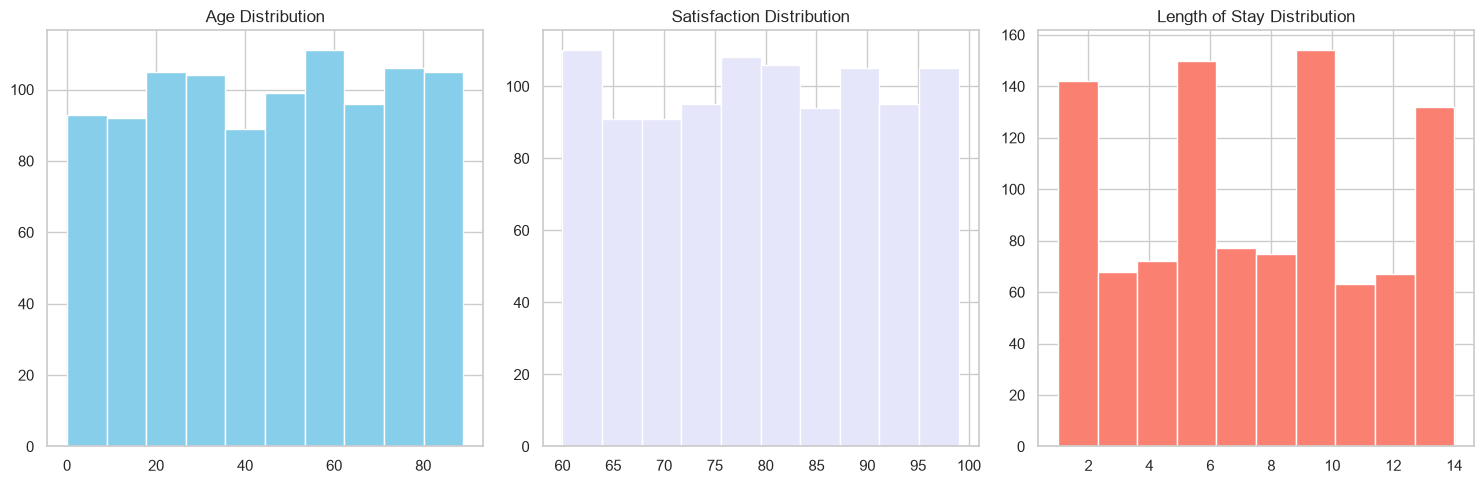

In [33]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
df['age'].hist(color="skyblue")
plt.title("Age Distribution")

plt.subplot(1,3,2)
df['satisfaction'].hist(color="lavender")
plt.title("Satisfaction Distribution")

plt.subplot(1,3,3)
df['length_of_stay'].hist(color="salmon")
plt.title("Length of Stay Distribution")

plt.tight_layout()
plt.show()

In [34]:
df.groupby('service')['satisfaction'].mean()
df.groupby('service')['length_of_stay'].mean()

service
ICU                 7.605809
emergency           7.159696
general_medicine    6.995868
surgery             7.866142
Name: length_of_stay, dtype: float64

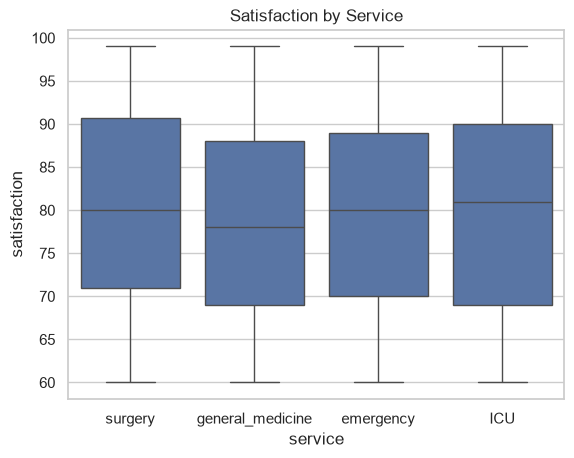

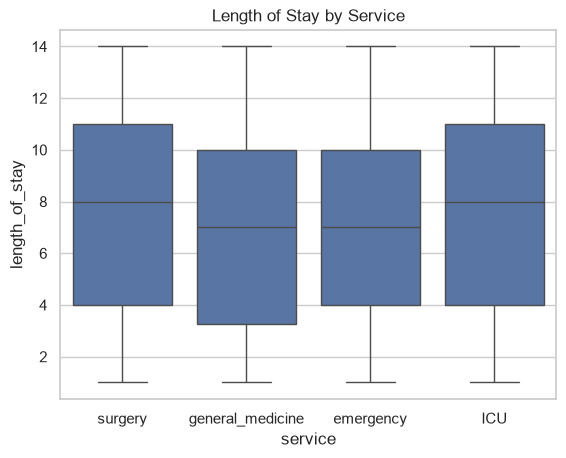

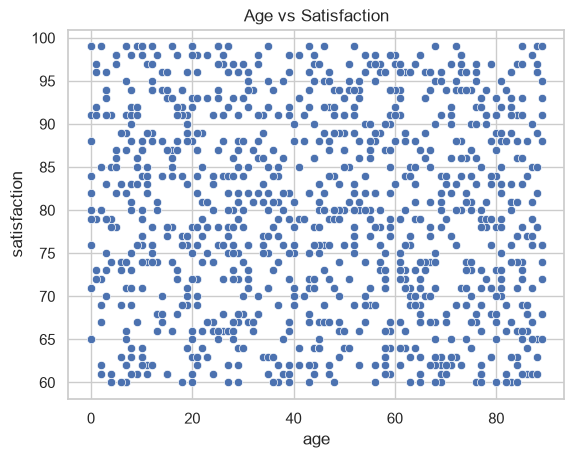

In [36]:
sns.boxplot(x="service", y="satisfaction", data=df)
plt.title("Satisfaction by Service")
plt.show()

sns.boxplot(x="service", y="length_of_stay", data=df)
plt.title("Length of Stay by Service")
plt.show()

sns.scatterplot(x="age", y="satisfaction", data=df)
plt.title("Age vs Satisfaction")
plt.show()


Text(0.5, 1.0, 'Correlation Heatmap')

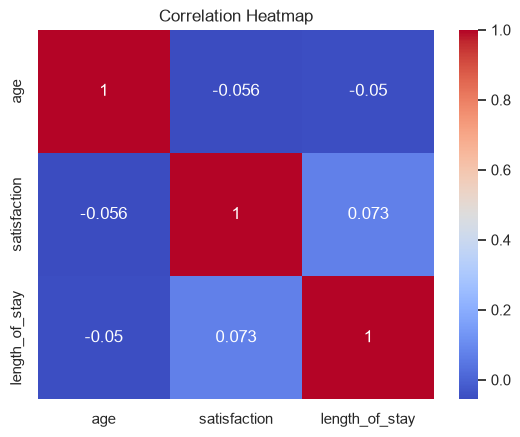

In [37]:
corr = df[['age','satisfaction','length_of_stay']].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")


Summary:
- ICU patients stay longest but are less satisfied
- Surgery are most satisfied overall
- Age does not affect satisfaction
- Older patients stay longer than younger ones
- Overall, the data suggests that patient satisfaction varies by service type, with surgery performing best. Length of stay is strongly influenced by the type of service and patient age.